In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

C:\Users\potab\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
train_data = pd.read_csv('sign_mnist_train.csv')
test_data = pd.read_csv('sign_mnist_test.csv')

print("Training data shape:", train_data.shape)
print("Testing data shape:", test_data.shape)

train_data.head()

Training data shape: (27455, 785)
Testing data shape: (7172, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,2,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,13,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179


In [8]:
X_train = train_data.drop('label', axis=1)
y_train = train_data['label']

X_test = test_data.drop('label', axis=1)
y_test = test_data['label']

In [9]:
anomaly_label = 24
X_normal = X_train[y_train != anomaly_label]

In [10]:
# Normalize pixel values
X_normal = X_normal / 255.0
X_test = X_test / 255.0

# Convert into NumPy arrays
X_normal = X_normal.to_numpy()
X_test = X_test.to_numpy()

# Reshape into 28x28 grayscale images
X_normal = X_normal.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Normal data shape:", X_normal.shape)
print("Testing data shape:", X_test.shape)

Normal data shape: (26337, 28, 28, 1)
Testing data shape: (7172, 28, 28, 1)


In [11]:
X_train_normal, X_val_normal = train_test_split(
    X_normal,
    test_size=0.1,
    random_state=42
)

In [13]:
model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2), padding='same'),
    layers.Conv2D(16, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2), padding='same'),
    layers.Conv2D(8, (3, 3), activation='relu', padding='same'),
    
    layers.UpSampling2D((2, 2)),
    layers.Conv2D(16, (3, 3), activation='relu', padding='same'),
    layers.UpSampling2D((2, 2)),
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(1, (3, 3), activation='sigmoid', padding='same')
])

In [14]:
model.compile(
    optimizer='adam',
    loss='mse'
)

In [17]:
# Train Autoencoder
history = model.fit(
    X_train_normal,
    X_train_normal,
    epochs=11,
    validation_data=(X_val_normal, X_val_normal),
)

Epoch 1/11
741/741 ━━━━━━━━━━━━━━━━━━━━ 22s 29ms/step - loss: 0.0019 - val_loss: 0.0019
Epoch 2/11
741/741 ━━━━━━━━━━━━━━━━━━━━ 21s 28ms/step - loss: 0.0019 - val_loss: 0.0018
Epoch 3/11
741/741 ━━━━━━━━━━━━━━━━━━━━ 20s 28ms/step - loss: 0.0018 - val_loss: 0.0018
Epoch 4/11
741/741 ━━━━━━━━━━━━━━━━━━━━ 20s 27ms/step - loss: 0.0018 - val_loss: 0.0018
Epoch 5/11
741/741 ━━━━━━━━━━━━━━━━━━━━ 21s 28ms/step - loss: 0.0018 - val_loss: 0.0017
Epoch 6/11
741/741 ━━━━━━━━━━━━━━━━━━━━ 21s 28ms/step - loss: 0.0017 - val_loss: 0.0018
Epoch 7/11
741/741 ━━━━━━━━━━━━━━━━━━━━ 21s 28ms/step - loss: 0.0017 - val_loss: 0.0017
Epoch 8/11
741/741 ━━━━━━━━━━━━━━━━━━━━ 21s 28ms/step - loss: 0.0017 - val_loss: 0.0016
Epoch 9/11
741/741 ━━━━━━━━━━━━━━━━━━━━ 21s 29ms/step - loss: 0.0016 - val_loss: 0.0016
Epoch 10/11
741/741 ━━━━━━━━━━━━━━━━━━━━ 20s 27ms/step - loss: 0.0016 - val_loss: 0.0016
Epoch 11/11
741/741 ━━━━━━━━━━━━━━━━━━━━ 20s 28ms/step - loss: 0.0016 - val_loss: 0.0016


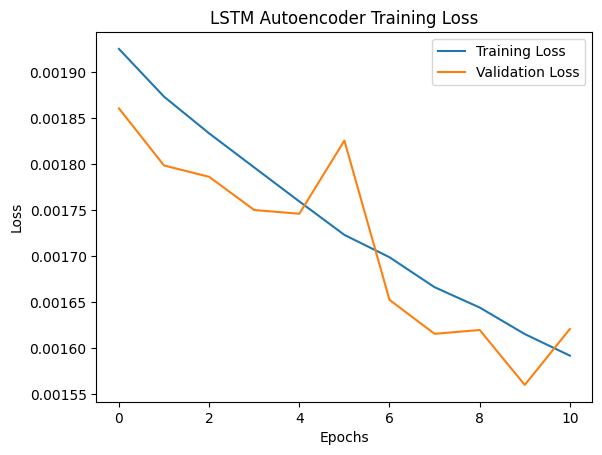

In [18]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('LSTM Autoencoder Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [19]:
X_train_pred = model.predict(X_train_normal)
X_test_pred = model.predict(X_test)

train_error = np.mean( np.square(X_train_normal - X_train_pred), axis=(1, 2, 3))
test_error = np.mean(np.square(X_test - X_test_pred), axis=(1, 2, 3))

threshold = np.percentile(train_error, 95)
print("Reconstruction Error Threshold:", threshold)

741/741 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step
225/225 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step
Reconstruction Error Threshold: 0.0031496829656488604


In [20]:
y_pred = (test_error > threshold).astype(int)

print("Predicted classes:")
print(y_pred[:20])

Predicted classes:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [21]:
y_actual = (y_test.to_numpy() == 24).astype(int)

              precision    recall  f1-score   support

           0       0.96      0.96      0.96      6840
           1       0.08      0.07      0.07       332

    accuracy                           0.92      7172
   macro avg       0.52      0.51      0.51      7172
weighted avg       0.91      0.92      0.92      7172



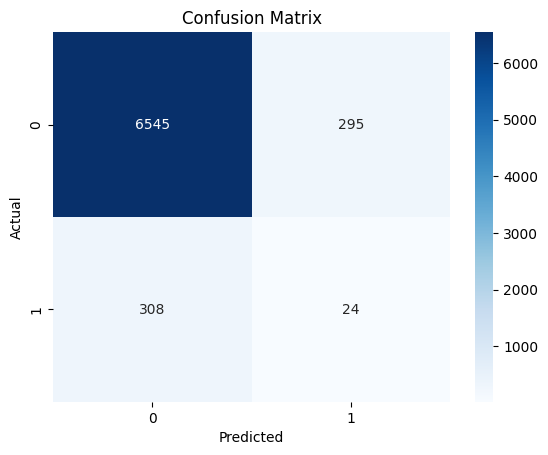

In [22]:
print(classification_report(y_actual, y_pred, zero_division = 0))

cm = confusion_matrix(y_actual, y_pred)
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()